---
title: "Figures: The Blanchard (1985) Model of Perpetual Youth"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

<!-- The book's notation for this notebook: a definition for each macro its Markdown uses, so that it renders in Jupyter. Written by code/notebook_math.py from the registry and the course block; don't edit. The student notebook leaves this cell out. -->
$\newcommand{\CNrm}{C}$
$\newcommand{\Debt}{D}$
$\newcommand{\deprRte}{\delta}$
$\newcommand{\diePrb}{\mathsf{d}}$
$\newcommand{\discRte}{\vartheta}$
$\newcommand{\discRteEff}{\mathring{\vartheta}}$
$\newcommand{\GoldRule}[1]{\bar{\bar{#1}}}$
$\newcommand{\kapShare}{\alpha}$
$\newcommand{\KNrm}{K}$
$\newcommand{\PermGroRte}{\mathsf{g}}$
$\newcommand{\rfree}{\mathsf{r}}$
$\newcommand{\Steady}{\bar}$
$\newcommand{\TaxLev}{T}$

Run this notebook in your browser, with nothing to install, in [JupyterLite](https://intertemporal-choice.github.io/lite/notebooks/index.html?path=BlanchardFiniteHorizon.ipynb); or open it in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/growth/BlanchardFiniteHorizon/BlanchardFiniteHorizon.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/growth/BlanchardFiniteHorizon/BlanchardFiniteHorizon.ipynb).

In [Blanchard's model of perpetual youth](https://intertemporal-choice.github.io/content/growth/blanchardfinitehorizon), every consumer dies with the same probability $\diePrb$ per unit of time, whatever the consumer's age, and is replaced by a newborn with no net worth, so the population stays at one and aggregates are also amounts per person. Utility is logarithmic and the time preference rate is $\discRte$, so every consumer spends the same share $\discRteEff = \discRte+\diePrb$ of total wealth. Output is $\KNrm^{\kapShare}$, capital depreciates at the rate $\deprRte$, and the interest rate is the net marginal product of capital, $\rfree = \kapShare\KNrm^{\kapShare-1}-\deprRte$. Aggregate capital and consumption move according to

$$
\dot{\KNrm} = \KNrm^{\kapShare} - \deprRte\KNrm - \CNrm, \qquad \dot{\CNrm} = (\rfree-\PermGroRte-\discRte)\CNrm - \discRteEff\left((\diePrb-\PermGroRte)\KNrm + \diePrb\Debt\right),
$$

where $\Debt$ is the government's debt, whose interest a lump-sum tax pays, and $\PermGroRte$ is the rate at which each consumer's income grows with age, negative when it falls. With neither, $\dot{\CNrm} = (\rfree-\discRte)\CNrm - \diePrb\discRteEff\KNrm$: each consumer's consumption grows at $\rfree-\discRte$, and the last term is the consumption lost as consumers who die, holding the average net worth, are replaced by newborns who hold none. (With both, the debt's term is different, as the chapter shows; the notebook never has both.) The notebook draws the phase diagram, what government debt does to it and to consumption over time, and the phase diagram when income falls with age.

In [ ]:
# Run anywhere: install the book's package (it brings numpy, scipy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    import importlib.util, sys
    if importlib.util.find_spec("pip"):
        %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io
    else:  # a Python without pip, as uv makes: install with uv, or say what to do
        !uv pip install -q --python {sys.executable} git+https://github.com/intertemporal-choice/intertemporal-choice.github.io || echo "Neither pip nor uv can install the book's package here: choose a kernel whose Python has pip, or the course's own environment."

In [ ]:
from dataclasses import dataclass, replace

import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

In [ ]:
import matplotlib.pyplot as plt

from intertemporal_choice import blanchard, notation, style

style.use_book_style()

## The economy

`Economy` holds the parameters of the RCK chapters' figures, without growth: $\kapShare = 0.3$, $\discRte = 0.02$ and $\deprRte = 0.08$, with the chapter's logarithmic utility. The death rate $\diePrb = 0.02$ is a horizon of 50 years, the chapter's example. The phase diagram and the two figures of the debt use $\diePrb = 0.05$, a horizon of 20 years, instead: with 50 years the steady state $\Steady{\KNrm} = 4.60$ is so close to the RCK model's $\Steady{\KNrm}_{\mathrm{RCK}} = 4.80$ that a phase diagram can barely show the gap, and the debt's effects are smaller still. The notebook's checks give the numbers for both horizons. The figure of income that falls with age keeps $\diePrb = 0.02$.

The $\dot{\CNrm}=0$ locus, $\CNrm = \discRteEff\left((\diePrb-\PermGroRte)\KNrm+\diePrb\Debt\right)/(\rfree-\PermGroRte-\discRte)$, lies where the interest rate exceeds $\discRte+\PermGroRte$, and rises without bound as capital approaches the line where $\rfree = \discRte+\PermGroRte$; with $\PermGroRte=0$, that line is the RCK model's steady state $\Steady{\KNrm}_{\mathrm{RCK}}$, where $\rfree = \discRte$. The $\dot{\KNrm}=0$ locus, $\CNrm = \KNrm^{\kapShare}-\deprRte\KNrm$, peaks at the golden rule $\GoldRule{\KNrm}$, where $\rfree = 0$.

In [ ]:
@dataclass(frozen=True)
class Economy:
    alpha: float = 0.3   # capital's share of output
    theta: float = 0.02  # time preference rate
    delta: float = 0.08  # depreciation rate
    d: float = 0.02      # death rate: the horizon is 1/d years
    g: float = 0.0       # growth rate of each consumer's income with age; negative when it falls
    D: float = 0.0       # government debt, constant; a lump-sum tax pays its interest

    @property
    def theta_ring(self):  # the time preference rate including death
        return self.theta + self.d


def interest(e, K):  # the net marginal product of capital
    return e.alpha * K ** (e.alpha - 1) - e.delta


def kdot(e, K, C):
    return K**e.alpha - e.delta * K - C


def cdot(e, K, C):
    if e.g != 0 and e.D != 0:
        raise ValueError("with income that falls with age, the debt's term in cdot is not d * theta_ring * D")
    return (interest(e, K) - e.g - e.theta) * C - e.theta_ring * ((e.d - e.g) * K + e.d * e.D)


def kdot_zero(e, K):  # consumption on the kdot = 0 locus
    return K**e.alpha - e.delta * K


def asymptote(e):
    """The capital where r = theta + g, which the cdot = 0 locus approaches as consumption rises; with g = 0,
    the RCK model's steady state. If income falls so fast that theta + g < -delta, r never gets that low: infinity."""
    if e.delta + e.theta + e.g <= 0:
        return np.inf
    return (e.alpha / (e.delta + e.theta + e.g)) ** (1 / (1 - e.alpha))


def cdot_zero(e, K):
    """Consumption on the cdot = 0 locus at each K below the asymptote; NaN at and beyond it."""
    K = np.asarray(K, float)
    gap = interest(e, K) - e.g - e.theta
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(gap > 0, e.theta_ring * ((e.d - e.g) * K + e.d * e.D) / gap, np.nan)


def golden_rule(e):  # the capital at the top of the kdot = 0 locus, where r = 0
    return (e.alpha / e.delta) ** (1 / (1 - e.alpha))


def steady_state(e):
    """(K, C) where the loci cross: below the asymptote, where the cdot = 0 locus rises from zero to infinity, and
    below the capital at which the kdot = 0 locus comes back down to zero."""
    top = min(asymptote(e), e.delta ** (-1 / (1 - e.alpha)))
    K = brentq(lambda K: kdot_zero(e, K) - float(cdot_zero(e, K)), 1e-6 * top, top * (1 - 1e-12), xtol=1e-14,
               rtol=1e-15)
    return K, kdot_zero(e, K)

## The saddle path, by time elimination

Along any path, $d\CNrm/d\KNrm = \dot{\CNrm}/\dot{\KNrm}$, a differential equation in $\KNrm$ alone. At a steady state both $\dot{\CNrm}$ and $\dot{\KNrm}$ are zero, so the equation is solved twice, outward from the steady state on each side, starting a small step away along the saddle path's slope there. That slope comes from the system linearized at the steady state: it is the direction of the eigenvector with the negative eigenvalue, the one direction from which the economy converges. `along_saddle` then follows capital over time along the saddle path, from a given capital stock.

In [ ]:
def jacobian(e, K, C):
    """The derivatives of (kdot, cdot) with respect to (K, C)."""
    r_prime = e.alpha * (e.alpha - 1) * K ** (e.alpha - 2)
    return np.array([
        [interest(e, K), -1.0],                                                       # d kdot/dK, d kdot/dC
        [r_prime * C - e.theta_ring * (e.d - e.g), interest(e, K) - e.g - e.theta],  # d cdot/dK, d cdot/dC
    ])


def saddle_slope(e):
    """dC/dK along the saddle path at the steady state."""
    values, vectors = np.linalg.eig(jacobian(e, *steady_state(e)))
    stable = vectors[:, np.argmin(values)]
    return stable[1] / stable[0]


def saddle_path(e, K_low, K_high):
    """The saddle path's consumption as a function of K on [K_low, K_high]."""
    K_ss, C_ss = steady_state(e)
    slope = saddle_slope(e)
    step = 1e-5 * K_ss
    branches = []
    for end, side in ((K_low, -1), (K_high, 1)):
        start = K_ss + side * step
        branches.append(solve_ivp(lambda K, C: cdot(e, K, C) / kdot(e, K, C), (start, end), [C_ss + slope * side * step],
                                  rtol=1e-11, atol=1e-13, dense_output=True).sol)
    below, above = branches

    def C(K):
        K = np.asarray(K, float)
        near = C_ss + slope * (K - K_ss)  # within a step of the steady state, the straight line between the branches
        return np.where(K < K_ss - step, below(np.minimum(K, K_ss - step))[0],
                        np.where(K > K_ss + step, above(np.maximum(K, K_ss + step))[0], near))

    return C


def along_saddle(e, saddle, K0, t):
    """Capital at the dates t, starting from K0 at date 0 and moving along the saddle path `saddle`."""
    run = solve_ivp(lambda _, K: [kdot(e, K[0], float(saddle(K[0])))], (0, t[-1]), [K0], rtol=1e-11, atol=1e-13,
                    dense_output=True)
    return run.sol(t)[0]


def motion(e, points):
    """The arrows of motion at each point (K, C): the signs of kdot and cdot there."""
    return [(K, C, np.sign(kdot(e, K, C)), np.sign(cdot(e, K, C))) for K, C in points]

## The phase diagram

With $\diePrb = 0.05$, the $\dot{\CNrm}=0$ locus rises from the origin and bends up toward the dashed line at $\Steady{\KNrm}_{\mathrm{RCK}}$, the RCK model's $\dot{\CNrm}=0$ locus, which it would become if $\diePrb$ were zero. It crosses the $\dot{\KNrm}=0$ locus at the steady state A, with less capital than the RCK model's steady state, which has less than the golden rule. The gray arrows show which way capital and consumption move in each region between the loci, and the saddle path is the one path that leads to A.

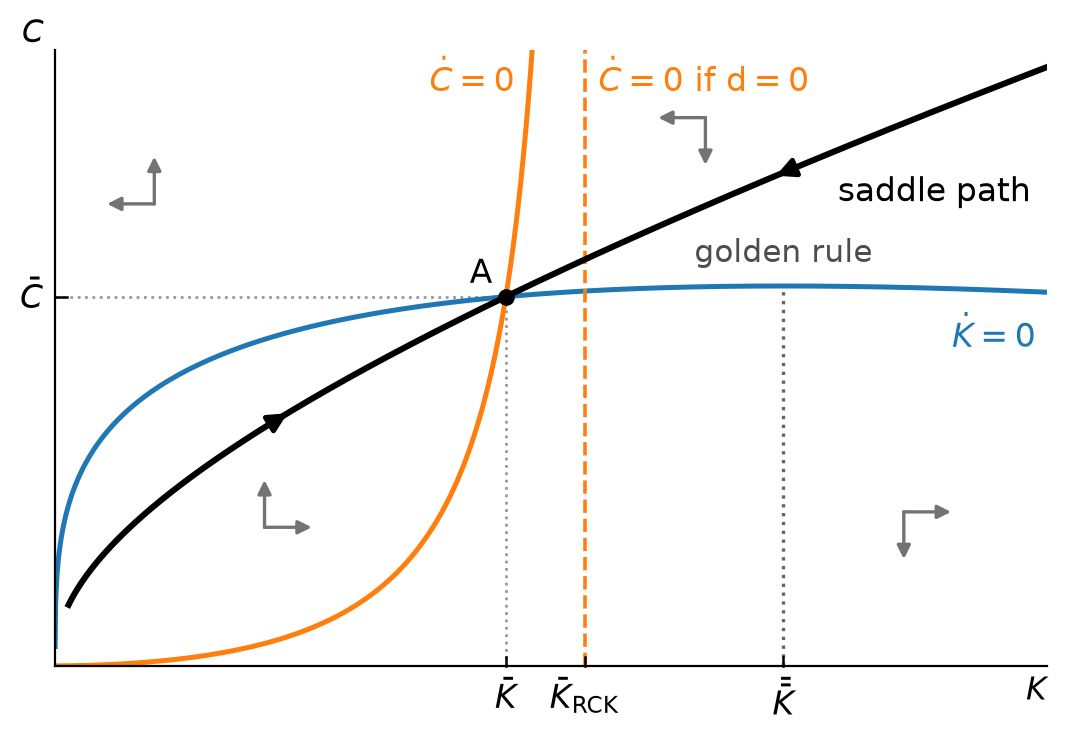

In [ ]:
e = Economy(d=0.05)  # a horizon of 20 years
K_ss, C_ss = steady_state(e)
K = np.linspace(1e-4, 9, 2000)
K_saddle = np.linspace(0.03 * K_ss, 9, 600)
saddle = saddle_path(e, K_saddle[0], K_saddle[-1])
fig, ax = plt.subplots()
blanchard.draw_phase(ax, K, kdot_zero(e, K), cdot_zero(e, K), (K_ss, C_ss), (K_saddle, saddle(K_saddle)),
                     (asymptote(e), notation.tex(r"$\dot{\CNrm}=0$ if $\diePrb=0$")), golden_rule(e),
                     motion(e, [(0.9, 1.5), (1.9, 0.45), (7.7, 0.5), (5.9, 1.78)]), c_max=2.0,
                     marks=[(asymptote(e), blanchard.K_RCK)], saddle_label_K=6.9)
style.save(fig, "BFHPhase")

## Government debt

At date 0, unexpectedly, the government issues debt $\Debt$ worth half of output at A and gives it to the consumers alive, and from then on it levies the lump-sum tax $\TaxLev = \rfree\Debt$ that pays the interest, so that the debt stays constant. The taxes cancel out of $\dot{\CNrm}$, and since they pay exactly the interest, capital accumulates as before: the only change in the equations of motion is the term $-\diePrb\discRteEff\Debt$ in $\dot{\CNrm}$. It moves the $\dot{\CNrm}=0$ locus up, or to the left, and leaves the $\dot{\KNrm}=0$ locus where it was, so the new steady state A′ has less capital and less consumption than A. At date 0 capital cannot jump, but consumption can: it jumps from A up onto the saddle path that leads to A′, and capital and consumption then fall along it. The figure is zoomed on the two steady states.

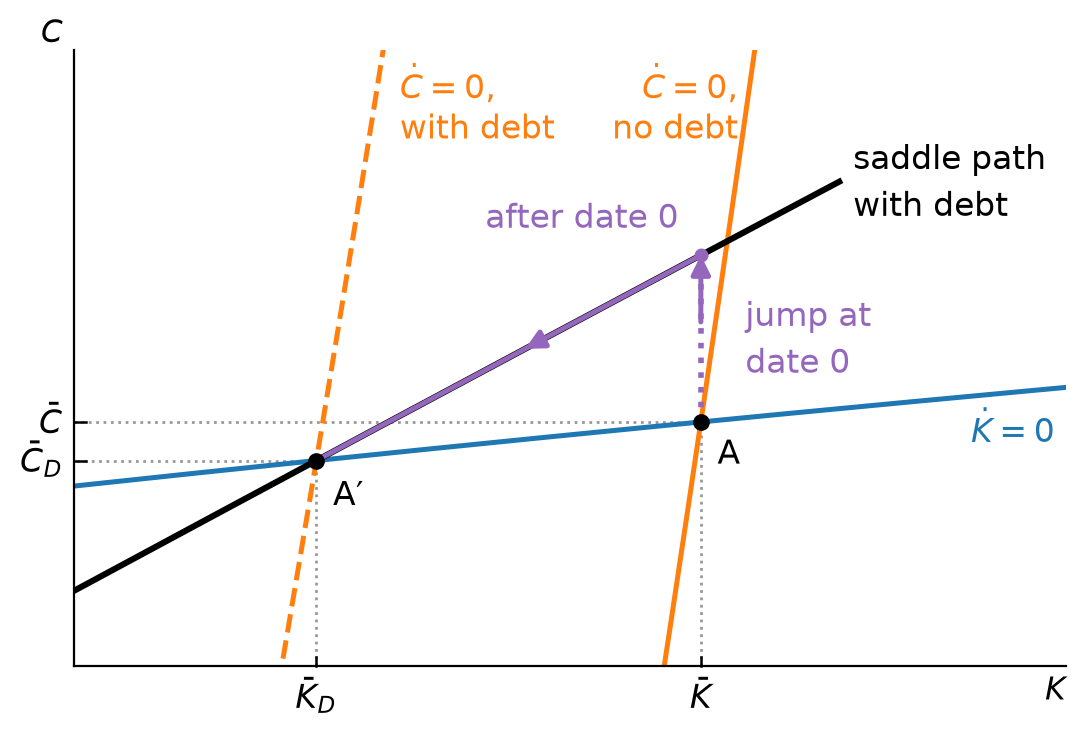

In [ ]:
debt = replace(e, D=0.5 * K_ss**e.alpha)  # half of output at A
K_D, C_D = steady_state(debt)
saddle_D = saddle_path(debt, 0.9 * K_D, 1.1 * K_ss)
C_jump = float(saddle_D(K_ss))  # consumption just after date 0: on the new saddle path, at the old capital
t = np.linspace(0, 60, 601)
K_t = along_saddle(debt, saddle_D, K_ss, t)
C_t = saddle_D(K_t)
gap, rise = K_ss - K_D, C_jump - C_D
window = ((K_D - 0.63 * gap, K_ss + 0.95 * gap), (C_D - rise, C_jump + rise))
K = np.linspace(*window[0], 400)
K_s = np.linspace(window[0][0], K_ss + 0.36 * gap, 300)  # the saddle path stops short of the edge, for its label
fig, ax = plt.subplots()
blanchard.draw_debt_phase(ax, K, kdot_zero(e, K), cdot_zero(e, K), cdot_zero(debt, K), (K_ss, C_ss), (K_D, C_D),
                          (K_s, saddle_D(K_s)), C_jump, (K_t, C_t), window)
style.save(fig, "BFHDebtPhase")

## Consumption over time

Until date 0 consumption is at its steady-state level $\Steady{\CNrm}$, at A. At date 0 it jumps up, and as capital runs down it falls, below $\Steady{\CNrm}$, toward the new steady-state level $\Steady{\CNrm}_{\Debt}$, at A′.

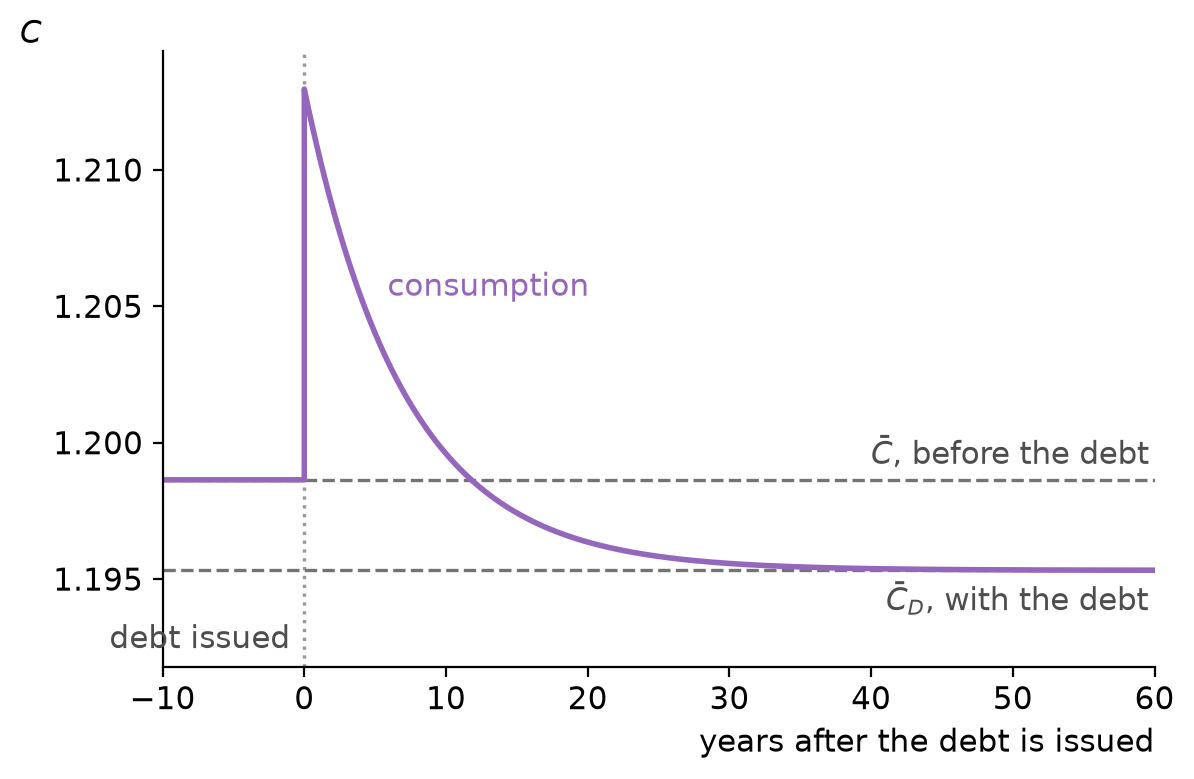

In [ ]:
before = np.linspace(-10, 0, 21)
fig, ax = plt.subplots()
blanchard.draw_consumption(ax, np.concatenate([before, t]), np.concatenate([np.full_like(before, C_ss), C_t]),
                           C_ss, C_D)
style.save(fig, "BFHDebtConsumption")

## Income that falls with age

Now each consumer's income falls with age, by 5 percent a year, $\PermGroRte = -0.05$, so that a newborn earns $(\diePrb-\PermGroRte)/\diePrb = 3.5$ times the average, and the horizon is again 50 years, $\diePrb = 0.02$. Consumers save while young for the years when their income will be lower, so much that the $\dot{\CNrm}=0$ locus, which now approaches the line where $\rfree = \discRte+\PermGroRte$, crosses the $\dot{\KNrm}=0$ locus to the right of its peak: the steady state A has more capital than the golden rule and a negative interest rate, so the economy is dynamically inefficient.

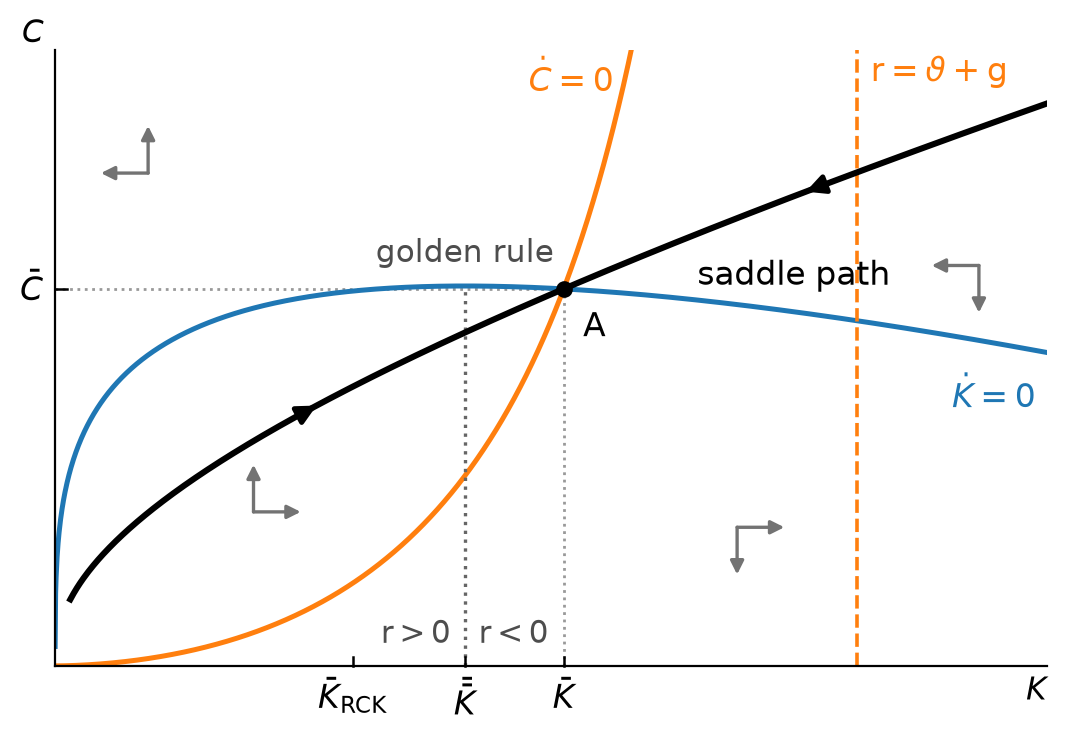

In [ ]:
falling = Economy(g=-0.05)  # d = 0.02, a horizon of 50 years
K_f, C_f = steady_state(falling)
K = np.linspace(1e-4, 16, 2000)
K_saddle = np.linspace(0.03 * K_f, 16, 600)
saddle_f = saddle_path(falling, K_saddle[0], K_saddle[-1])
fig, ax = plt.subplots()
blanchard.draw_phase(ax, K, kdot_zero(falling, K), cdot_zero(falling, K), (K_f, C_f), (K_saddle, saddle_f(K_saddle)),
                     (asymptote(falling), notation.tex(r"$\rfree=\discRte+\PermGroRte$")), golden_rule(falling),
                     motion(falling, [(1.5, 1.6), (3.2, 0.5), (11.0, 0.45), (14.9, 1.3)]), c_max=2.0,
                     marks=[(asymptote(Economy()), blanchard.K_RCK)],
                     rate_signs=(notation.tex(r"$\rfree>0$"), notation.tex(r"$\rfree<0$")), saddle_label_K=10.0,
                     a_offset=(7, -17))
style.save(fig, "BFHFallingIncome")

## Checks

The numbers the chapter and the figures' notes quote, and the properties of the loci and paths the figures show.

In [ ]:
r = lambda e, K: 100 * interest(e, K)  # percent
# The RCK model's steady state and the golden rule; this model's steady state with each horizon.
assert round(asymptote(Economy()), 3) == 4.804 and round(golden_rule(e), 3) == 6.608
long = Economy()  # d = 0.02
K_long, C_long = steady_state(long)
assert round(K_ss, 3) == 4.089 and round(C_ss, 4) == 1.1986 and round(r(e, K_ss), 2) == 3.19
assert round(K_long, 3) == 4.603 and round(C_long, 4) == 1.2127 and round(r(long, K_long), 2) == 2.30
# At A both loci hold, and r exceeds theta: (r - theta) C = d theta_ring K.
for econ, (K_a, C_a) in ((e, (K_ss, C_ss)), (long, (K_long, C_long))):
    assert abs(kdot(econ, K_a, C_a)) < 1e-12 and abs(cdot(econ, K_a, C_a)) < 1e-12 and interest(econ, K_a) > econ.theta
# Shorter horizons mean less capital; as d -> 0 the steady state approaches the RCK model's.
assert K_ss < K_long < asymptote(e) < golden_rule(e)
assert abs(steady_state(Economy(d=1e-7))[0] - asymptote(Economy())) < 1e-3
# Each steady state is a saddle point: one negative eigenvalue, one positive.
for econ in (e, long, debt, falling):
    values = np.linalg.eigvals(jacobian(econ, *steady_state(econ)))
    assert values.min() < 0 < values.max()
# The debt: half of output at A; A' has less capital, a higher interest rate and less consumption.
assert np.isclose(debt.D, 0.5 * K_ss**e.alpha) and round(debt.D, 3) == 0.763
assert K_D < K_ss and C_D < C_ss and interest(debt, K_D) > interest(e, K_ss)
assert round(100 * (K_D / K_ss - 1), 1) == -2.5 and round(r(debt, K_D), 2) == 3.39
# Consumption jumps up at date 0 and then falls, through its old level and on toward C_D; capital falls throughout.
assert C_jump > C_ss and np.all(np.diff(C_t) < 0) and np.all(np.diff(K_t) < 0) and abs(C_t[-1] - C_D) < 1e-5
crossing = np.interp(0, -(C_t - C_ss), t)  # C_t falls, so -(C_t - C_ss) rises through zero
assert 11 < crossing < 13
# The figures' notes: consumption jumps 1.2 percent, and C_D is 0.28 percent below C-bar.
assert round(100 * (C_jump / C_ss - 1), 1) == 1.2 and round(100 * (C_D / C_ss - 1), 2) == -0.28
# The saddle path solves the equations: started on it, the economy comes within a ten-thousandth of A'.
run = solve_ivp(lambda _, y: [kdot(debt, *y), cdot(debt, *y)], (0, 60), [K_ss, C_jump], rtol=1e-11, atol=1e-13)
assert np.min(np.hypot(run.y[0] / K_D - 1, run.y[1] / C_D - 1)) < 1e-4


def experiment(econ):
    """The debt of half of output at A in the economy econ: the indebted economy, A, A', consumption just after date 0,
    and the date when consumption is back at its old level."""
    K_a, C_a = steady_state(econ)
    owed = replace(econ, D=0.5 * K_a**econ.alpha)
    K_b, C_b = steady_state(owed)
    path = saddle_path(owed, 0.9 * K_b, 1.1 * K_a)
    dates = np.linspace(0, 60, 6001)
    C_path = path(along_saddle(owed, path, K_a, dates))
    return owed, (K_a, C_a), (K_b, C_b), float(path(K_a)), np.interp(0, -(C_path - C_a), dates)


# With the chapter's 50-year horizon the effects are smaller: capital falls 0.7 percent, from 4.603 to 4.571, r rises
# from 2.30 to 2.35 percent, and consumption jumps 0.34 percent, from 1.2127 to 1.2168, is back at its old level about
# 15 years later, and settles 0.06 percent below it, at 1.2119.
owed, (K_a, C_a), (K_b, C_b), jump_long, crossing_long = experiment(long)
assert round(owed.D, 2) == 0.79 and round(K_b, 3) == 4.571 and round(r(owed, K_b), 2) == 2.35
assert round(jump_long, 4) == 1.2168 and round(100 * (jump_long / C_a - 1), 2) == 0.34 and round(C_b, 4) == 1.2119
assert 14 < crossing_long < 15.5 and round(100 * (C_b / C_a - 1), 2) == -0.06
# Income falling 5 percent a year: capital beyond the golden rule, a negative interest rate.
assert round(K_f, 2) == 8.20 and K_f > golden_rule(falling) and round(r(falling, K_f), 1) == -1.1
assert round(asymptote(falling), 1) == 12.9 and round((falling.d - falling.g) / falling.d, 1) == 3.5
# The interest rate turns negative once income falls about 3.1 percent a year; however fast it falls, the rate stays
# above alpha (theta + d) - (1 - alpha) delta, which is negative only because (1 - alpha) delta > alpha (theta + d).
g_zero = brentq(lambda g: interest(falling, steady_state(replace(falling, g=g))[0]), -0.049, -0.021)
floor = falling.alpha * falling.theta_ring - (1 - falling.alpha) * falling.delta
assert round(g_zero, 3) == -0.031 and round(100 * floor, 1) == -4.4
fast = [interest(falling, steady_state(replace(falling, g=g))[0]) for g in (-0.1, -1.0, -100.0)]
assert all(x > floor for x in fast) and np.all(np.diff(fast) < 0) and fast[-1] - floor < 1e-3
print(f"d = 0.05: K = {K_ss:.3f}, C = {C_ss:.4f}, r = {r(e, K_ss):.2f}% "
      f"(d = 0.02: K = {K_long:.3f}, r = {r(long, K_long):.2f}%); K_RCK = {asymptote(e):.3f}, golden rule {golden_rule(e):.3f}")
print(f"debt {debt.D:.3f}: K {K_ss:.3f} -> {K_D:.3f} ({100 * (K_D / K_ss - 1):.1f}%), "
      f"r {r(e, K_ss):.2f} -> {r(debt, K_D):.2f}%, C jumps {100 * (C_jump / C_ss - 1):.2f}% to {C_jump:.4f}, "
      f"back at {C_ss:.4f} after {crossing:.1f} years, settles at {C_D:.4f} ({100 * (C_D / C_ss - 1):.2f}%)")
print(f"with d = 0.02: debt {owed.D:.3f}, K {K_a:.3f} -> {K_b:.3f}, C jumps {100 * (jump_long / C_a - 1):.2f}% "
      f"to {jump_long:.4f}, back after {crossing_long:.1f} years, settles at {C_b:.4f}")
print(f"falling income: K = {K_f:.2f}, r = {r(falling, K_f):.2f}%, asymptote {asymptote(falling):.2f}; "
      f"r < 0 once g < {g_zero:.4f}; floor {100 * floor:.1f}%")

d = 0.05: K = 4.089, C = 1.1986, r = 3.19% (d = 0.02: K = 4.603, r = 2.30%); K_RCK = 4.804, golden rule 6.608
debt 0.763: K 4.089 -> 3.988 (-2.5%), r 3.19 -> 3.39%, C jumps 1.20% to 1.2130, back at 1.1986 after 11.8 years, settles at 1.1953 (-0.28%)
with d = 0.02: debt 0.790, K 4.603 -> 4.571, C jumps 0.34% to 1.2168, back after 14.6 years, settles at 1.2119
falling income: K = 8.20, r = -1.12%, asymptote 12.93; r < 0 once g < -0.0309; floor -4.4%
